# Cas pratiques complets : calculs et simulations

Chaque section reprend un cas pratique du cours. Faites les calculs à la main d'abord, puis vérifiez ici.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Fonctions utiles

In [2]:
z = stats.norm.ppf
def var_tvar_discrete(valeurs, probas, alpha):
    valeurs, probas = np.asarray(valeurs, float), np.asarray(probas, float)
    F = np.cumsum(probas); i = np.argmax(F >= alpha - 1e-12); v = valeurs[i]; m = valeurs > v
    return v, (np.sum(valeurs[m]*probas[m]) + v*(F[i] - alpha)) / (1 - alpha)

def collectif(lam, mu, s, n_sim, cap=None, seed=42):
    r = np.random.default_rng(seed)
    N = r.poisson(lam, n_sim); X = r.lognormal(mu, s, N.sum())
    if cap is not None: X = np.minimum(X, cap)
    S = np.bincount(np.repeat(np.arange(n_sim), N), weights=X, minlength=n_sim)
    v = np.quantile(S, 0.999, method='inverted_cdf')
    return S.mean(), v, S[S > v].mean()

## Cas 1 : risque de crédit d'une institution de microfinance

Perte par defaut : 180000.0 | EL : 3600000.0
Independance      E=20.0 sd=4.38 q99=31 VaR=5,580,000 TVaR=5,858,524 capital=1,980,000 P(N>=30)=0.0196 marge=2.5980%
Avec conjoncture  E=20.0 sd=10.91 q99=50 VaR=9,000,000 TVaR=9,531,511 capital=5,400,000 P(N>=30)=0.1928 marge=2.9400%


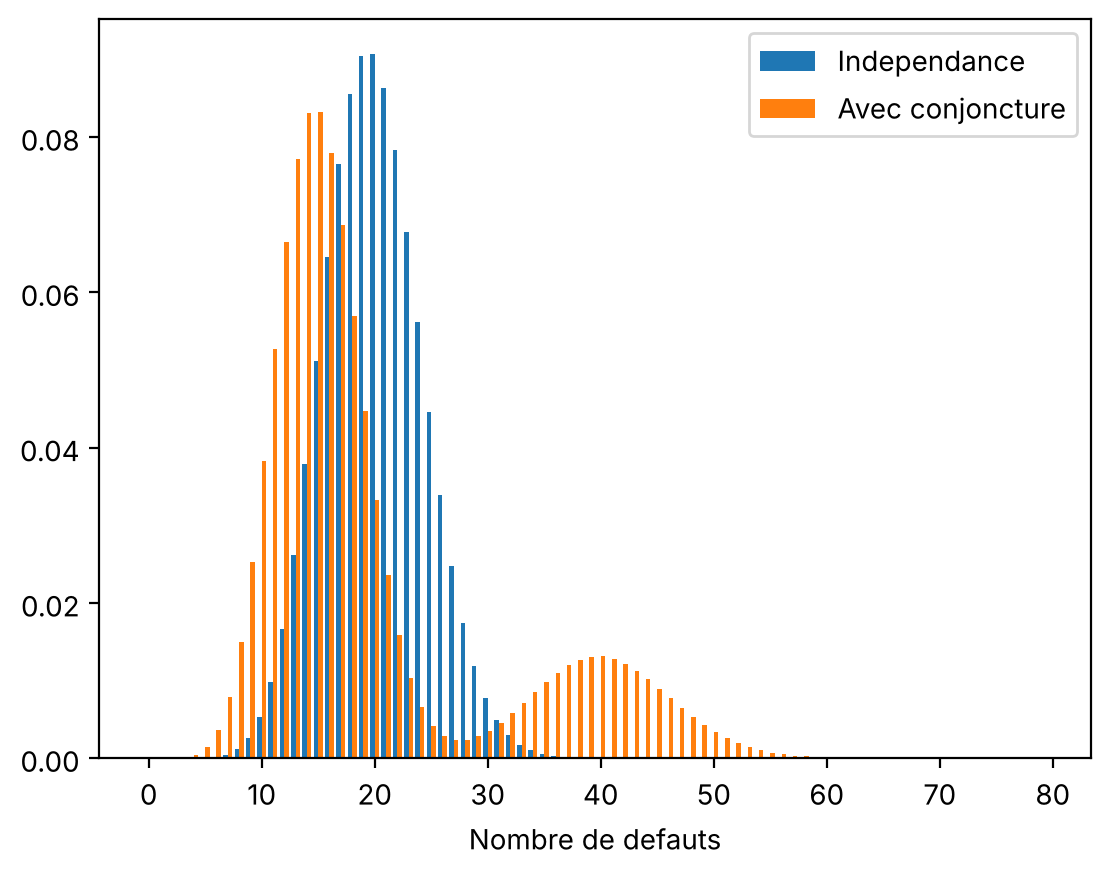

In [3]:
n, L = 500, 0.6*300_000
EL = n*0.04*L; print('Perte par defaut :', L, '| EL :', EL)
k = np.arange(n + 1)
p_ind = stats.binom(n, 0.04).pmf(k)
p_mel = 0.8*stats.binom(n, 0.03).pmf(k) + 0.2*stats.binom(n, 0.08).pmf(k)
for nom, p in [('Independance', p_ind), ('Avec conjoncture', p_mel)]:
    E = k @ p; sd = np.sqrt(k**2 @ p - E**2)
    q, t = var_tvar_discrete(k, p, 0.99)
    cap = q*L - EL
    print(f'{nom:17s} E={E:.1f} sd={sd:.2f} q99={q:.0f} VaR={q*L:,.0f} TVaR={t*L:,.0f} capital={cap:,.0f} '
          f'P(N>=30)={p[30:].sum():.4f} marge={(EL + 0.15*cap)/(n*300_000):.4%}')
plt.bar(k[:80] - 0.2, p_ind[:80], width=0.4, label='Independance')
plt.bar(k[:80] + 0.2, p_mel[:80], width=0.4, label='Avec conjoncture')
plt.xlabel('Nombre de defauts'); plt.legend(); plt.show()

## Cas 2 : risque de marché d'une caisse de retraite

In [4]:
V0 = 500e6
w = np.array([0.50, 0.35, 0.15]); s = np.array([0.20, 0.05, 0.01])
C = np.array([[1, 0.2, 0], [0.2, 1, 0.3], [0, 0.3, 1]])
Sigma = np.outer(s, s) * C; print(Sigma)
sp = np.sqrt(w @ Sigma @ w); s10 = sp*np.sqrt(10/250)
print('Volatilite annuelle :', sp, '| a 10 jours :', s10)
print('VaR 99 % 10 j :', z(0.99)*s10*V0, '| ES 97,5 % :', stats.norm.pdf(z(0.975))/0.025*s10*V0)
print('Part du risque (%) :', 100*w*(Sigma @ w)/sp**2)
vi = z(0.99)*s*np.sqrt(10/250)*w*V0; print('VaR par classe :', vi, 'somme :', vi.sum(), 'gain :', vi.sum() - z(0.99)*s10*V0)
nu = 4; c = np.sqrt((nu - 2)/nu); T = stats.t(nu)
q_t = T.ppf(0.99)*c; es_t = T.expect(lambda x: x, lb=T.ppf(0.975))/0.025*c
print('Student(4) : VaR', q_t*s10*V0, 'ES', es_t*s10*V0)
print('Stress test :', (0.5*0.20 + 0.35*0.03)*V0)

[[0.04    0.002   0.     ]
 [0.002   0.0025  0.00015]
 [0.      0.00015 0.0001 ]]
Volatilite annuelle : 0.10499642851068793 | a 10 jours : 0.020999285702137587
VaR 99 % 10 j : 24425821.824772 | ES 97,5 % : 24546094.374346253
Part du risque (%) : [9.38839377e+01 6.02421933e+00 9.18429825e-02]
VaR par classe : [23263478.74040841  4071108.77957147   348952.18110613] somme : 27683539.701086007 gain : 3257717.8763140067
Student(4) : VaR 27818718.75808502 ES 29649639.601462424
Stress test : 55250000.0


## Cas 3 : assurance indicielle sécheresse

P(indemnite) : 0.11506967022170822 | P(plafond) : 0.00015910859015753364
Sans plafond (formule) : 7012.80633964539
E[I] par hectare : 7007.917462613064 | prime pure totale : 14015834.92522613
R a 1 % : 818.4130314897898 | VaR 99 % : 281586968.5102102 | TVaR 99 % : 365325922.61820906
VaR si hectares independants : 16756016.643201616
Capital : 267571133.5849841 | prime totale : 40772948.28372454 | par hectare : 20386.47414186227


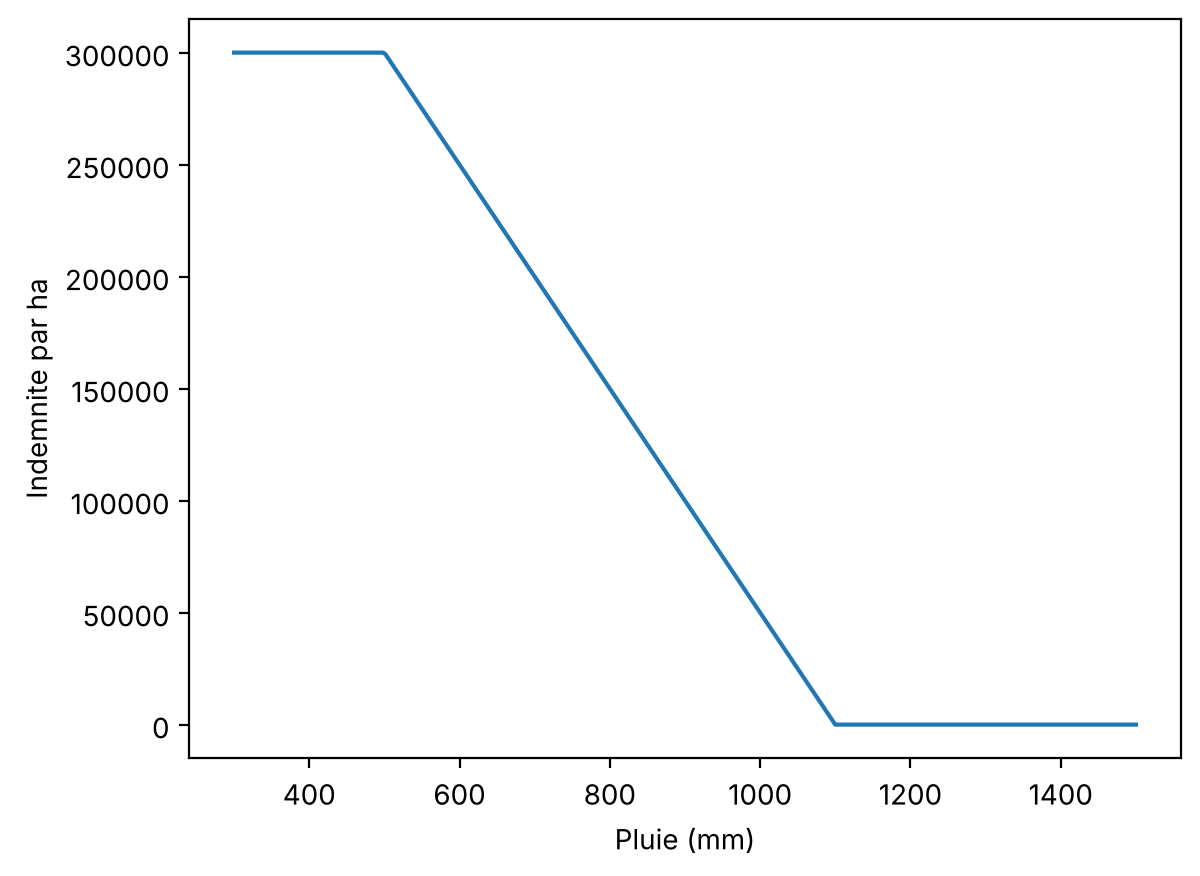

In [5]:
R = stats.norm(1400, 250)
I = lambda r: np.minimum(500*np.maximum(1100 - r, 0), 300_000)
print('P(indemnite) :', R.cdf(1100), '| P(plafond) :', R.cdf(500))
d = -1.2; print('Sans plafond (formule) :', 500*((1100 - 1400)*stats.norm.cdf(d) + 250*stats.norm.pdf(d)))
EI = integrate.quad(lambda r: I(r)*R.pdf(r), -np.inf, 1100)[0]
EI2 = integrate.quad(lambda r: I(r)**2*R.pdf(r), -np.inf, 1100)[0]; sdI = np.sqrt(EI2 - EI**2)
print('E[I] par hectare :', EI, '| prime pure totale :', 2000*EI)
r01 = R.ppf(0.01); var_tot = 2000*I(r01)
u = np.linspace(1e-8, 0.01, 200_001); tvar_tot = 2000*np.mean(I(R.ppf(u)))
print('R a 1 % :', r01, '| VaR 99 % :', var_tot, '| TVaR 99 % :', tvar_tot)
print('VaR si hectares independants :', 2000*EI + z(0.99)*np.sqrt(2000)*sdI)
cap = var_tot - 2000*EI; prime = 2000*EI + 0.10*cap
print('Capital :', cap, '| prime totale :', prime, '| par hectare :', prime/2000)
rr = np.linspace(300, 1500, 400); plt.plot(rr, I(rr)); plt.xlabel('Pluie (mm)'); plt.ylabel('Indemnite par ha'); plt.show()

## Cas 4 : risque opérationnel de fraude interne
La simulation d'un million d'années prend quelques secondes par option.

In [6]:
mu, s = 15, 1.5
LN = stats.lognorm(s=s, scale=np.exp(mu))
print('Mediane :', LN.median(), '| moyenne :', LN.mean(), '| P(X > 100 M) :', LN.sf(1e8), '| EL :', 4*LN.mean())
dd = 1e8
cede = np.exp(mu + s**2/2)*stats.norm.cdf((mu + s**2 - np.log(dd))/s) - dd*stats.norm.cdf((mu - np.log(dd))/s)
print('Charge cedee par fraude :', cede, '| prime annuelle :', 1.3*4*cede)
options = {'Rien': (4, None, 0), 'A seule': (3, None, 5e6), 'B seule': (4, dd, 1.3*4*cede), 'A et B': (3, dd, 5e6 + 1.3*3*cede)}
for nom, (lam, cap_, cout) in options.items():
    E, v, t = collectif(lam, mu, s, 1_000_000, cap_)
    capital = v - E
    print(f'{nom:8s} EL={E/1e6:6.1f} VaR={v/1e6:6.1f} TVaR={t/1e6:7.1f} capital={capital/1e6:6.1f} cout total={(E + cout + 0.12*capital)/1e6:6.1f} (millions)')

Mediane : 3269017.3724721107 | moyenne : 10069282.390094347 | P(X > 100 M) : 0.011290393079849118 | EL : 40277129.56037739
Charge cedee par fraude : 1061652.8700454386 | prime annuelle : 5520594.924236281


Rien     EL=  40.3 VaR= 659.1 TVaR=  997.1 capital= 618.9 cout total= 114.5 (millions)
A seule  EL=  30.2 VaR= 582.7 TVaR=  904.5 capital= 552.5 cout total= 101.5 (millions)


B seule  EL=  36.0 VaR= 232.0 TVaR=  260.1 capital= 196.0 cout total=  65.0 (millions)
A et B   EL=  27.0 VaR= 207.5 TVaR=  231.8 capital= 180.5 cout total=  57.8 (millions)


## Cas 5 : prévoyance décès et scénario d'épidémie

In [7]:
k = np.arange(1001)
B = stats.binom(1000, 0.004)
print('E[N] :', B.mean(), '| q99,5 exact :', B.ppf(0.995), '| normale :', 4 + z(0.995)*np.sqrt(1000*0.004*0.996), '| Poisson :', stats.poisson(4).ppf(0.995))
p0 = B.pmf(k); p1 = 0.98*p0 + 0.02*stats.binom(1000, 0.012).pmf(k)
for nom, p in [('Sans epidemie', p0), ('Avec epidemie', p1)]:
    E = (k @ p)*5e6; v, t = var_tvar_discrete(k*5e6, p, 0.995)
    print(f'{nom:14s} prime pure={E/1e6:.1f} VaR={v/1e6:.0f} TVaR={t/1e6:.1f} capital={(v - E)/1e6:.1f} '
          f'P(N>=10)={p[10:].sum():.4f} prime commerciale/salarie={(E + 0.1*(v - E))/1000:,.0f}')
print('Piege : moyenne des quantiles =', 0.98*10 + 0.02*stats.binom(1000, 0.012).ppf(0.995))

E[N] : 4.0 | q99,5 exact : 10.0 | normale : 9.141344965908097 | Poisson : 10.0
Sans epidemie  prime pure=20.0 VaR=50 TVaR=54.0 capital=30.0 P(N>=10)=0.0080 prime commerciale/salarie=23,000
Avec epidemie  prime pure=20.8 VaR=70 TVaR=82.5 capital=49.2 P(N>=10)=0.0230 prime commerciale/salarie=25,720
Piege : moyenne des quantiles = 10.24
